In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
class Problem:
    def __init__(self, path="../TSPA.csv"):
        self.df = pd.read_csv(path, sep=";", header=None)

        cord = self.df.values[:, :-1]
        dist = np.sqrt(np.sum((cord[None, :, :] - cord[:, None, :]) ** 2, axis=2))

        self.dist = np.floor(dist + 0.5).astype(int)
        self.cost = self.df.values[:, -1]

    def get_n(self):
        return len(self.df)

    def get_n_nodes(self):
        # 50% of the nodes, rounded up
        return (self.get_n() + 1) // 2

    def eval(self, nodes: np.array, end=True):
        assert nodes.dtype == np.int64
        assert len(set(nodes)) == len(nodes)

        n_nodes = self.get_n_nodes()
        if end == True and len(nodes) != n_nodes:
            raise ValueError("The final path does not have the required length!")

        pairs = np.column_stack((nodes, np.roll(nodes, -1)))
        if not end:
            pairs = pairs[:-1]
        total_length = np.sum(self.dist[pairs[:, 0], pairs[:, 1]])
        total_cost = np.sum(self.cost[nodes])

        return total_length + total_cost


In [3]:
def eval(f: callable, p: Problem, iter=None):
    # by default one run per node, the i-th run starts from node i
    if iter is None:
        iter = p.get_n()

    values = []
    best = None
    best_val = float("inf")

    for i in range(iter):
        solution = f(p, start=i % p.get_n())
        val = p.eval(solution)
        values.append(val)
        if val < best_val:
            best = solution
            best_val = val

    values = np.array(values)

    print(f"Min: {np.min(values)}")
    print(f"Max: {np.max(values)}")
    print(f"Mean: {np.mean(values)}")

    return best, values

## Methods from assignment 1

Random solution and NN (end only) are the same as before. NN (any position) and greedy cycle are written below as special cases of the general insertion heuristic (weights `w_regret=0, w_greedy=1`), which gives exactly the same solutions as the implementation from assignment 1 (same tie breaking: the lowest node index, then the first position).

In [4]:
def random_solution(problem: Problem, start=None):
    n = problem.get_n()
    return np.random.choice(n, size=problem.get_n_nodes(), replace=False)


def nearest_neighbor_end(problem: Problem, start=None):
    n = problem.get_n()
    n_nodes = problem.get_n_nodes()
    if start is None:
        start = np.random.randint(n)

    path = [start]
    unvisited = np.ones(n, dtype=bool)
    unvisited[start] = False

    while len(path) < n_nodes:
        scores = problem.dist[path[-1]] + problem.cost
        scores = np.where(unvisited, scores, np.inf)
        nxt = int(np.argmin(scores))
        path.append(nxt)
        unvisited[nxt] = False

    return np.array(path, dtype=np.int64)

## Insertion costs

`insertion_deltas` returns a matrix with one row per candidate node and one column per insertion position. Column `i` means `solution.insert(i, j)`, and the value is the change of the objective function (added distance + node cost).

- Path (NN any position): position 0 is before the first node, position `len(path)` is after the last node, others are between two neighbours. The path is closed only at the end.
- Cycle (greedy cycle): position `i` is the edge between `cycle[i - 1]` and `cycle[i]`, so position 0 is the closing edge.

In [5]:
def insertion_deltas(problem: Problem, solution, candidates, cycle: bool):
    d = problem.dist
    s = np.array(solution)

    if cycle:
        a, b = np.roll(s, 1), s
        delta = d[candidates][:, a] + d[candidates][:, b] - d[a, b][None, :]
    else:
        a, b = s[:-1], s[1:]
        front = d[candidates, s[0]][:, None]
        middle = d[candidates][:, a] + d[candidates][:, b] - d[a, b][None, :]
        back = d[candidates, s[-1]][:, None]
        delta = np.hstack([front, middle, back])

    return delta + problem.cost[candidates][:, None]

## Greedy 2-regret heuristics

For every candidate node we compute the best and the second best insertion cost. The 2-regret is their difference. The score of a node is

`score = w_regret * regret - w_greedy * best_delta`

and we insert the node with the highest score at its best position.

- `w_regret=1, w_greedy=0` - pure greedy 2-regret,
- `w_regret=1, w_greedy=1` - weighted sum (2-regret + best change of the objective), equal weights,
- `w_regret=0, w_greedy=1` - plain greedy (NN any position / greedy cycle from assignment 1).

Ties in the score are broken by the smaller best delta (then by the lower node index). This matters in the first step: with a one-node path (or a two-node cycle) all insertion positions give the same solution, so every regret is 0 and the pure regret version would otherwise just take the node with the lowest index.

In [6]:
def regret_heuristic(problem: Problem, start=None, cycle=True, w_regret=1, w_greedy=1):
    n = problem.get_n()
    n_nodes = problem.get_n_nodes()
    if start is None:
        start = np.random.randint(n)

    d = problem.dist

    if cycle:
        # same start as greedy cycle: the second node closes a 2-node cycle
        scores = 2 * d[start] + problem.cost
        scores = np.where(np.arange(n) != start, scores, np.inf)
        solution = [start, int(np.argmin(scores))]
    else:
        solution = [start]

    visited = np.zeros(n, dtype=bool)
    visited[solution] = True

    while len(solution) < n_nodes:
        candidates = np.flatnonzero(~visited)
        delta = insertion_deltas(problem, solution, candidates, cycle)

        two_best = np.sort(delta, axis=1)[:, :2]
        best_delta = two_best[:, 0]
        regret = two_best[:, -1] - best_delta
        score = w_regret * regret - w_greedy * best_delta

        # highest score, then smallest best delta, then lowest node index
        idx = np.lexsort((candidates, best_delta, -score))[0]
        pos = int(np.argmin(delta[idx]))

        solution.insert(pos, int(candidates[idx]))
        visited[candidates[idx]] = True

    return np.array(solution, dtype=np.int64)

In [7]:
def nearest_neighbor_any(problem, start=None):
    return regret_heuristic(problem, start, cycle=False, w_regret=0, w_greedy=1)

def greedy_cycle(problem, start=None):
    return regret_heuristic(problem, start, cycle=True, w_regret=0, w_greedy=1)

def regret_nn_any(problem, start=None):
    return regret_heuristic(problem, start, cycle=False, w_regret=1, w_greedy=0)

def regret_greedy_cycle(problem, start=None):
    return regret_heuristic(problem, start, cycle=True, w_regret=1, w_greedy=0)

def weighted_regret_nn_any(problem, start=None):
    return regret_heuristic(problem, start, cycle=False, w_regret=1, w_greedy=1)

def weighted_regret_greedy_cycle(problem, start=None):
    return regret_heuristic(problem, start, cycle=True, w_regret=1, w_greedy=1)


methods = {
    "Random": random_solution,
    "NN (end only)": nearest_neighbor_end,
    "NN (any position)": nearest_neighbor_any,
    "Greedy cycle": greedy_cycle,
    "2-regret (NN any position)": regret_nn_any,
    "2-regret (greedy cycle)": regret_greedy_cycle,
    "Weighted 2-regret (NN any position)": weighted_regret_nn_any,
    "Weighted 2-regret (greedy cycle)": weighted_regret_greedy_cycle,
}
new_methods = list(methods)[4:]

## Experiment

Each greedy method is run 200 times per instance, once from every node. Random solution is generated 200 times.

In [8]:
np.random.seed(0)
problems = {name: Problem(f"../{name}.csv") for name in ["TSPA", "TSPB"]}

results = {}
best_solutions = {}
for name, p in problems.items():
    for method, f in methods.items():
        print(f"{name} / {method}")
        best, values = eval(f, p)
        results[(method, name)] = values
        best_solutions[(method, name)] = best

TSPA / Random
Min: 238989
Max: 290456
Mean: 262874.39
TSPA / NN (end only)
Min: 84362
Max: 90075
Mean: 87476.63
TSPA / NN (any position)


Min: 72328
Max: 77022
Mean: 74346.965
TSPA / Greedy cycle


Min: 72590
Max: 75345
Mean: 73792.87
TSPA / 2-regret (NN any position)


Min: 110950
Max: 135771
Mean: 121360.29
TSPA / 2-regret (greedy cycle)


Min: 112806
Max: 128089
Mean: 120378.765
TSPA / Weighted 2-regret (NN any position)


...

Min: 55655
Max: 63736
Mean: 59777.5
TSPB / 2-regret (NN any position)


Min: 68761
Max: 79756
Mean: 73649.84
TSPB / 2-regret (greedy cycle)


Min: 68150
Max: 77274
Mean: 72484.84
TSPB / Weighted 2-regret (NN any position)


Min: 50485
Max: 61406
Mean: 55698.94
TSPB / Weighted 2-regret (greedy cycle)


Min: 52906
Max: 63326
Mean: 57766.23


In [9]:
rows = []
for method in methods:
    row = {"Method": method}
    for name in problems:
        v = results[(method, name)]
        row[f"{name} min"] = v.min()
        row[f"{name} max"] = v.max()
        row[f"{name} mean"] = round(v.mean(), 2)
    rows.append(row)
summary = pd.DataFrame(rows)
summary

,Method,TSPA min,TSPA max,TSPA mean,TSPB min,TSPB max,TSPB mean
0,Random,238989,290456,262874.39,185119,225987,206009.68
1,NN (end only),84362,90075,87476.63,56007,63166,59397.34
2,NN (any position),72328,77022,74346.96,52915,66164,59475.50
3,Greedy cycle,72590,75345,73792.87,55655,63736,59777.50
4,2-regret (NN any position),110950,135771,121360.29,68761,79756,73649.84
5,2-regret (greedy cycle),112806,128089,120378.76,68150,77274,72484.84
6,Weighted 2-regret (NN any position),72419,78504,75549.36,50485,61406,55698.94
7,Weighted 2-regret (greedy cycle),72011,75532,73349.74,52906,63326,57766.23


## Solution check

Independent check of the best solutions: the right number of distinct nodes, valid indices, and the objective recomputed from scratch with plain loops.

In [10]:
for (method, name), s in best_solutions.items():
    p = problems[name]
    nodes = [int(x) for x in s]
    assert len(nodes) == p.get_n_nodes()
    assert len(set(nodes)) == len(nodes)
    assert all(0 <= x < p.get_n() for x in nodes)

    length = sum(p.dist[nodes[i], nodes[(i + 1) % len(nodes)]] for i in range(len(nodes)))
    cost = sum(p.cost[x] for x in nodes)
    assert length + cost == results[(method, name)].min()
print("All best solutions are valid")

All best solutions are valid


## Visualization

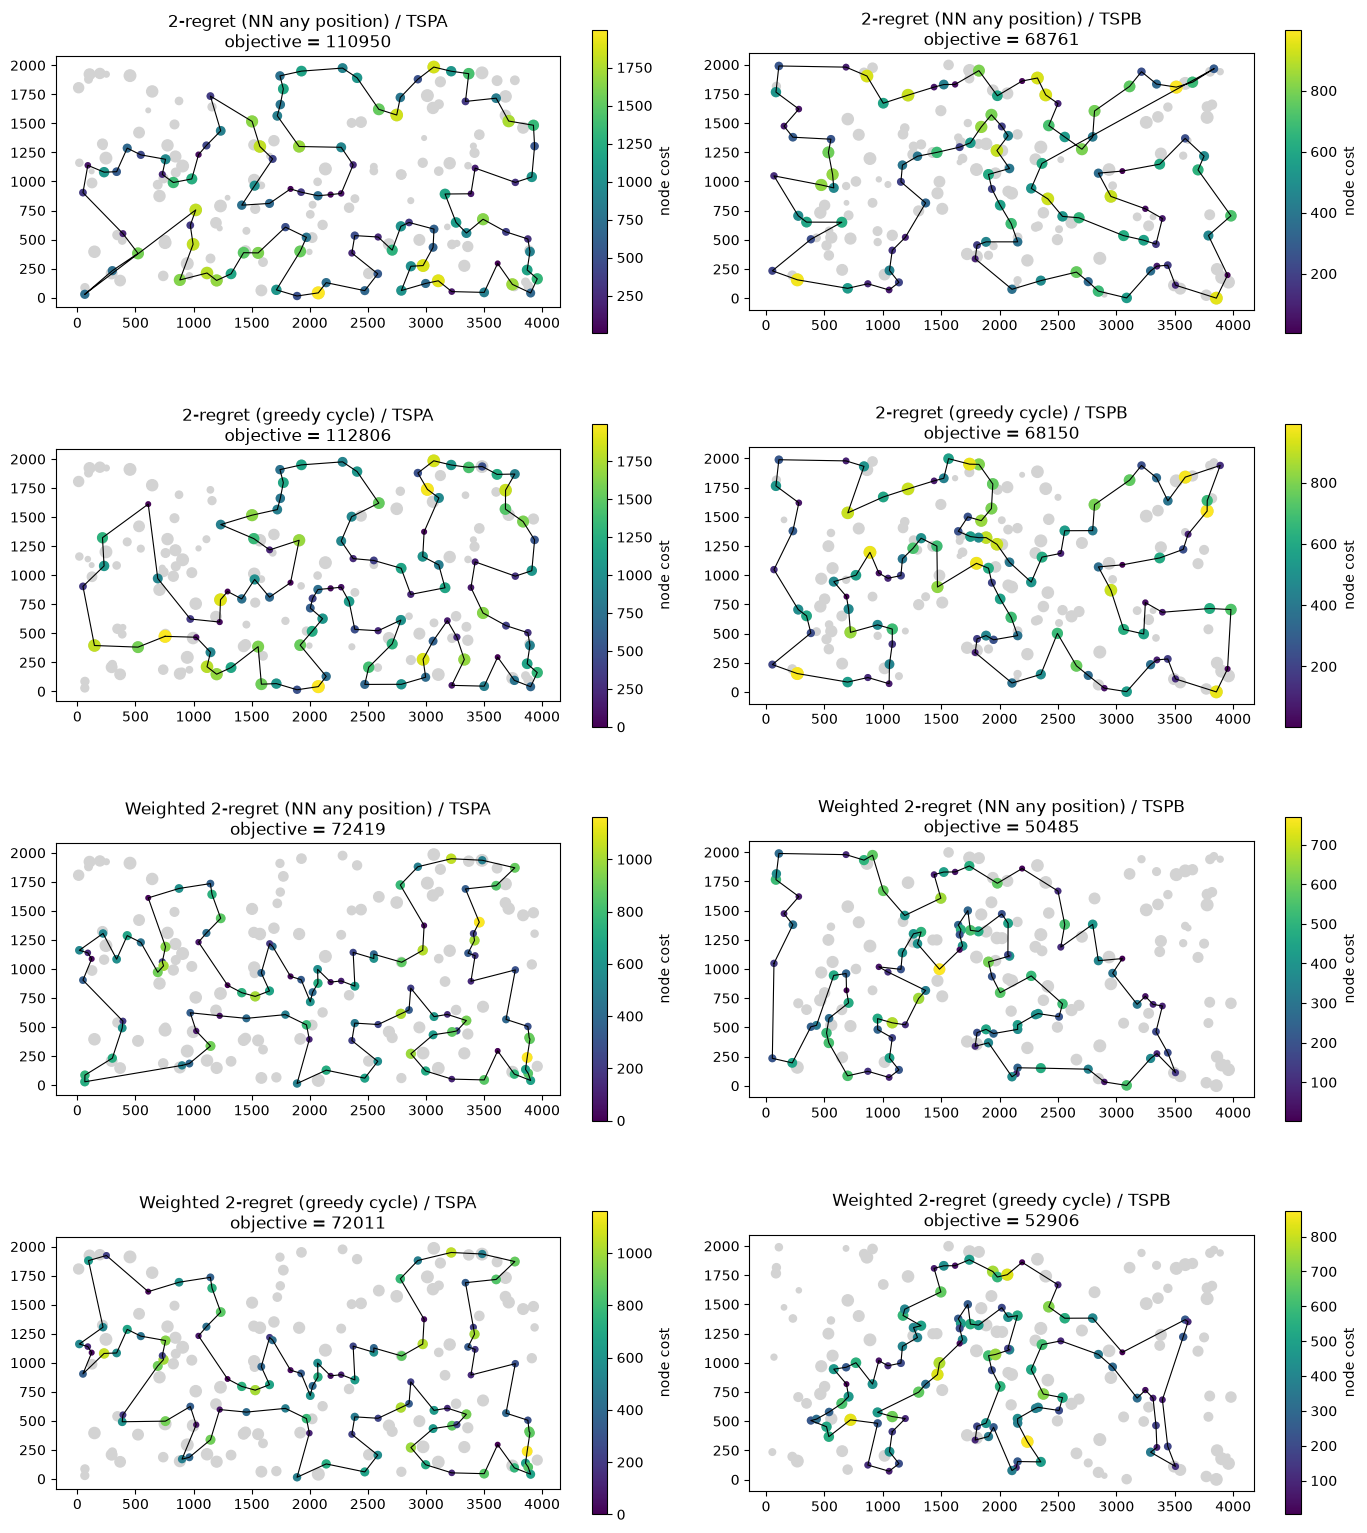

In [11]:
fig, axes = plt.subplots(len(new_methods), len(problems), figsize=(7 * len(problems), 4 * len(new_methods)), squeeze=False)

for col, (name, p) in enumerate(problems.items()):
    x, y, cost = p.df[0].values, p.df[1].values, p.df[2].values
    sizes = 10 + 60 * cost / cost.max()

    for row, method in enumerate(new_methods):
        ax = axes[row, col]
        solution = best_solutions[(method, name)]
        cycle = np.append(solution, solution[0])

        # all nodes in gray, selected nodes colored by cost, size also by cost
        ax.scatter(x, y, s=sizes, c="lightgray")
        ax.plot(x[cycle], y[cycle], c="black", linewidth=0.8)
        points = ax.scatter(x[solution], y[solution], s=sizes[solution], c=cost[solution], cmap="viridis")

        ax.set_title(f"{method} / {name}\nobjective = {p.eval(solution)}")
        ax.set_aspect("equal")
        fig.colorbar(points, ax=ax, label="node cost", shrink=0.8)

fig.tight_layout()
fig.savefig("solutions.png", dpi=120)
plt.show()

## Best solutions

In [12]:
for method in new_methods:
    for name in problems:
        s = best_solutions[(method, name)]
        print(f"{method} / {name} ({problems[name].eval(s)}):")
        print(", ".join(str(x) for x in s))
        print()

2-regret (NN any position) / TSPA (110950):
104, 69, 120, 97, 168, 149, 11, 49, 108, 152, 100, 123, 148, 162, 132, 76, 4, 157, 18, 173, 16, 156, 28, 185, 67, 144, 179, 177, 36, 33, 143, 190, 139, 112, 5, 115, 175, 39, 154, 34, 109, 186, 136, 197, 163, 19, 178, 101, 155, 21, 147, 37, 47, 50, 93, 81, 43, 113, 117, 130, 159, 170, 75, 26, 78, 122, 107, 64, 57, 105, 182, 111, 138, 165, 151, 150, 176, 72, 65, 134, 84, 58, 158, 192, 181, 118, 114, 25, 121, 73, 45, 70, 96, 10, 183, 166, 32, 40, 30, 23

2-regret (NN any position) / TSPB (68761):
94, 169, 199, 70, 190, 194, 77, 104, 144, 185, 79, 57, 83, 44, 89, 156, 164, 96, 198, 121, 195, 50, 7, 116, 37, 13, 149, 28, 145, 158, 138, 55, 177, 53, 65, 178, 103, 180, 132, 1, 108, 62, 175, 134, 45, 157, 60, 40, 64, 47, 38, 21, 168, 172, 8, 92, 166, 72, 46, 109, 3, 122, 151, 98, 25, 181, 73, 59, 85, 82, 88, 163, 99, 39, 17, 74, 20, 14, 2, 23, 110, 118, 131, 143, 148, 196, 78, 54, 162, 106, 127, 90, 153, 182, 150, 84, 66, 35, 27, 135

2-regret (greed

## Extra: other weights

Weighted version with different weights of the regret (the weight of the best change of the objective is 1).

In [13]:
rows = []
for w in [0.25, 0.5, 1, 2, 4]:
    row = {"w_regret": w}
    for name, p in problems.items():
        for label, cycle in [("NN any", False), ("cycle", True)]:
            values = np.array([
                p.eval(regret_heuristic(p, start, cycle=cycle, w_regret=w, w_greedy=1))
                for start in range(p.get_n())
            ])
            row[f"{name} {label} mean"] = round(values.mean(), 2)
            row[f"{name} {label} min"] = values.min()
    rows.append(row)
weights = pd.DataFrame(rows)
weights

,w_regret,TSPA NN any mean,TSPA NN any min,TSPA cycle mean,TSPA cycle min,TSPB NN any mean,TSPB NN any min,TSPB cycle mean,TSPB cycle min
0,0.25,74982.28,72758,73845.90,72430,57085.50,52203,56407.76,52924
1,0.50,75279.73,72134,73187.40,72049,56150.76,52302,55694.02,52351
2,1.00,75549.36,72419,73349.74,72011,55698.94,50485,57766.23,52906
3,2.00,76408.12,73614,74271.08,72575,54710.06,51286,59713.24,52796
4,4.00,79765.55,76584,76715.16,73880,57077.48,54123,57132.58,53651
